In [14]:
from pandas import pandas as pd
import matplotlib.pyplot as plt,seaborn as sns, openpyxl

In [2]:
path = r"H:\Python\etapa3-pandas\data\CD2022_Populacao_2010_Compatibilizada_20231222 (1) (1).xlsx"


df = pd.read_excel(path,header=2)
df

,Unnamed: 0,UF,COD. UF,COD. MUNIC,NOME DO MUNICÍPIO,População Município 2010\n(Sinopse),População 2010 (Alterações de Limites até 2022)1,População Censo 2022
0,NaN,RO,11.0,15.0,Alta Floresta D'Oeste,24392.0,24392.0,21494.0
1,NaN,RO,11.0,23.0,Ariquemes,90353.0,90353.0,96833.0
2,NaN,RO,11.0,31.0,Cabixi,6313.0,6313.0,5351.0
3,NaN,RO,11.0,49.0,Cacoal,78574.0,78574.0,86887.0
4,NaN,RO,11.0,56.0,Cerejeiras,17029.0,17029.0,15890.0
...,...,...,...,...,...,...,...,...
5569,NaN,DF,53.0,108.0,Brasília,2570160.0,2572159.0,2817381.0
5570,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5571,NaN,Nota: Para o cálculo das taxas de crescimento ...,NaN,NaN,NaN,NaN,NaN,NaN
5572,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df_formatado = df.iloc[2:5570, 1:]
df_formatado = df_formatado.rename(columns={"UF": "UF", 
                             "COD. UF": "COD. UF", 
                             "NOME DO MUNICÍPIO":"MUNICIPIO", 
                             "População Município 2010\n(Sinopse)" : "2010", 
                             "População 2010 (Alterações de Limites até 2022)1": "2010(1)", 
                             "População Censo 2022": "2022" 
})
df_formatado



,UF,COD. UF,COD. MUNIC,MUNICIPIO,2010,2010(1),2022
2,RO,11.0,31.0,Cabixi,6313.0,6313.0,5351.0
3,RO,11.0,49.0,Cacoal,78574.0,78574.0,86887.0
4,RO,11.0,56.0,Cerejeiras,17029.0,17029.0,15890.0
5,RO,11.0,64.0,Colorado do Oeste,18591.0,18591.0,15663.0
6,RO,11.0,72.0,Corumbiara,8783.0,8783.0,7519.0
...,...,...,...,...,...,...,...
5565,GO,52.0,22005.0,Vianópolis,12548.0,12548.0,14956.0
5566,GO,52.0,22054.0,Vicentinópolis,7371.0,7373.0,8768.0
5567,GO,52.0,22203.0,Vila Boa,4735.0,4735.0,4215.0
5568,GO,52.0,22302.0,Vila Propício,5145.0,5145.0,5815.0


In [4]:
df_formatado["2010"] = df_formatado["2010"].astype(str)

In [5]:
df_formatado["2010"] = df_formatado["2010"].astype(float).dropna()

In [6]:


pop_estado = (
    df_formatado.groupby("UF")[["2010", "2022"]]
    .sum()
    .reset_index())

pop_estado.to_csv("data/pop_estado.csv", index = False, encoding= "utf-8")

In [9]:
pop_estado_tratada = pop_estado.copy()

pop_estado_tratada.columns = [
    "UF",
    "2010",
    "2022"
]
pop_estado_tratada["crescimento"] = pop_estado_tratada["2022"] - pop_estado_tratada["2010"]

pop_estado_tratada = pop_estado_tratada.sort_values(by = 'crescimento', ascending = False)

pop_estado_tratada = pop_estado_tratada.reset_index(drop=True)

pop_estado_tratada





,UF,2010,2022,crescimento
0,SP,41262199.0,44411238.0,3149039.0
1,SC,6248436.0,7610361.0,1361925.0
2,GO,6003788.0,7056495.0,1052707.0
3,PR,10444526.0,11444380.0,999854.0
4,MG,19597330.0,20539989.0,942659.0
5,MT,3035122.0,3658649.0,623527.0
6,PA,7581051.0,8120131.0,539080.0
7,AM,3483985.0,3941613.0,457628.0
8,CE,8452381.0,8794957.0,342576.0
9,ES,3514952.0,3833712.0,318760.0


In [ ]:
pop_estado_tratada.to_csv("data/pop_estado_tratada.csv", index = False, encoding= "utf-8", sep=";")


In [20]:

top10 = (
    pop_estado_tratada
    .nlargest(10, "crescimento")
    .sort_values("crescimento", ascending=True)
)

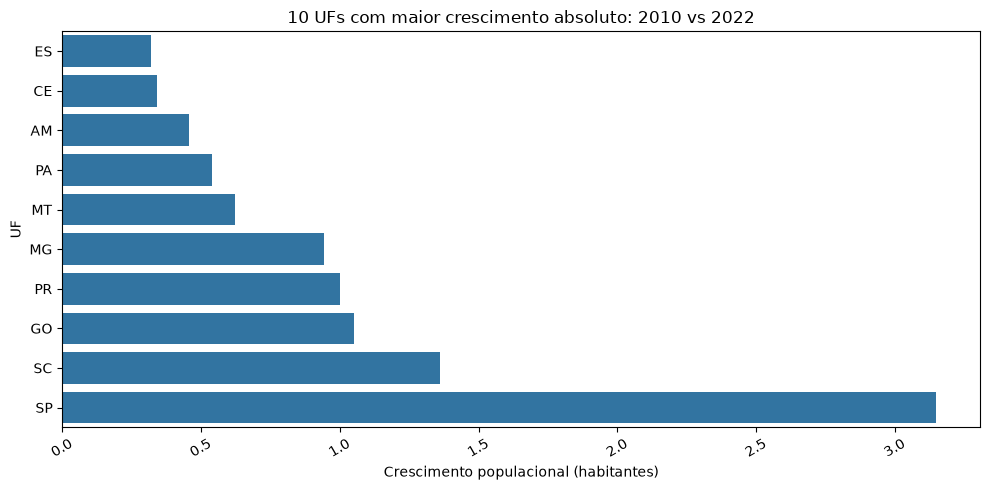

In [30]:



fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=top10, x="crescimento", y="UF", ax=ax)
ax.set_title("10 UFs com maior crescimento absoluto: 2010 vs 2022")
ax.set_xlabel("Crescimento populacional (habitantes)")
ax.set_ylabel("UF")
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"{x/1_000_000:.1f}")
)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


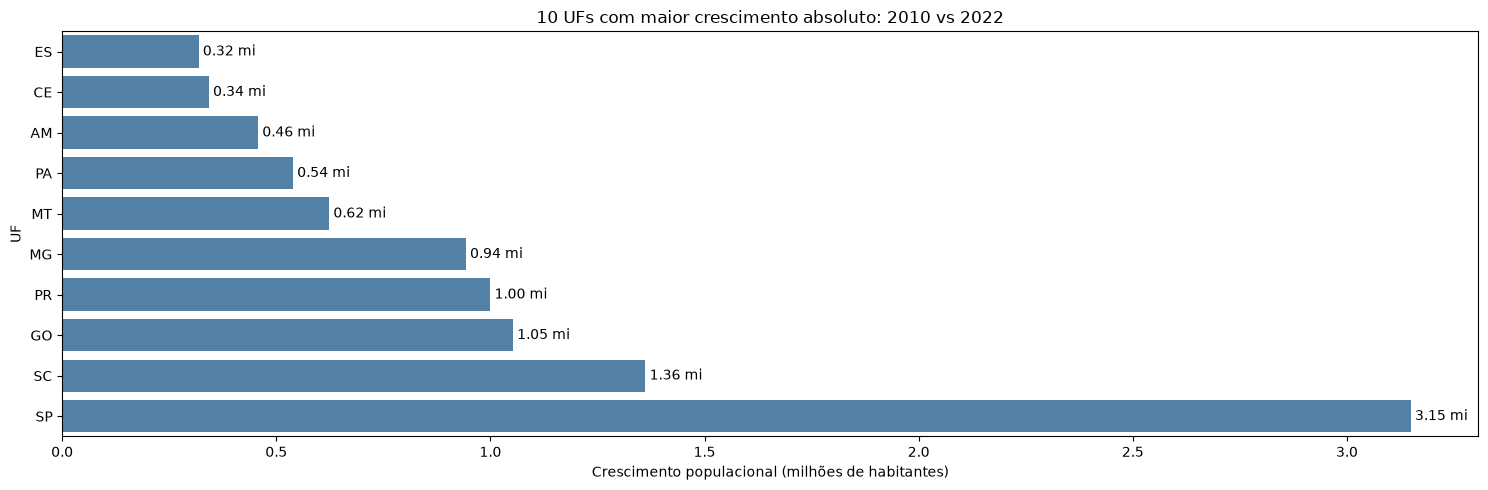

In [34]:
fig, ax = plt.subplots(figsize=(15, 5))

sns.barplot(
    data=top10,
    x="crescimento",
    y="UF",
    ax=ax,
    color="steelblue"
)

ax.set_title("10 UFs com maior crescimento absoluto: 2010 vs 2022")
ax.set_xlabel("Crescimento populacional (milhões de habitantes)")
ax.set_ylabel("UF")

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"{x/1_000_000:.1f}")
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{v/1_000_000:.2f} mi" for v in top10["crescimento"]],
        padding=3
    )

plt.tight_layout()
plt.show()